# 01 — OPEX Data Preparation & Accounting Hygiene

Stage 1 end-to-end preparation of the `seed = 42` Pharmaceutical OPEX dataset (`v2.2.2-freeze`):
1. **Setup & Data Inventory:** Load canonical SAP tables via `opex_forecast.io.load_pharma_table()` (see [00_sap_column_reference.ipynb](00_sap_column_reference.ipynb) for SAP ↔ readable column lookup).
2. **Accounting Hygiene & 4-Condition Filter Waterfall:** Verify double-entry balance and reconcile Total Ledger -> OPEX -> Regular Periods (`1–12`) -> Recurring Operational OPEX (`SPECIAL_ITEM_FLAG == "NONE"`).
3. **GAAP vs. Adjusted Operational & FX Bridge:** Isolate non-recurring GAAP Special Items and compare Reported USD (`KSL`) vs. Constant-FX USD (`KSL_BUDGET_FX`).
4. **Point-in-Time (`CPUDT`) Close-Window Demonstration:** Compare `2025-06-10` vs. `2025-06-30` cutoffs on June 2025 postings.
5. **Single-Snapshot `COOI` & Causal Feature Audit:** Build and inspect `opex_monthly_panel.parquet` with readable `UPPER_SNAKE` column names.
6. **Tie-Out Assertion:** Verify exact dollar parity between the exported Parquet panel and `acdoca_universal_journal.csv`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from opex_forecast.column_map import rename_to_readable
from opex_forecast.config import DOCS_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR
from opex_forecast.data_prep.prepare_opex_panel import (
    audit_universal_journal,
    build_monthly_opex_panel,
    extract_hygiene_diagnostics,
)
from opex_forecast.io import load_pharma_table

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Load primary journal + GL dim once and pass into Stage 1 helpers to avoid re-reading CSVs
uj_raw = load_pharma_table("acdoca_universal_journal")
dim_gl = load_pharma_table("dim_gl_account")

dd_summary = (
    pd.read_csv(DOCS_DIR / "pharma_opex_v22_data_dictionary.csv")
    .groupby("table_name", as_index=False, sort=False)
    .agg(ROWS=("row_count", "first"), COLS=("col_ordinal", "max"))
)
print(f"RAW_DATA_DIR: {RAW_DATA_DIR}")
dd_summary

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\adars\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


RAW_DATA_DIR: D:\Code Projects\opex_forecast\data\raw\pharma_v22


,table_name,ROWS,COLS
0,dim_company_code,3,4
1,dim_plant,6,6
2,dim_cost_center,24,13
3,dim_profit_center,17,5
4,dim_gl_account,26,8
5,dim_fx_rates,504,6
6,fact_opex_drivers,1152,21
7,plan_drivers,1440,13
8,fact_po_commitments,26598,16
9,acdoca_actuals,75268,30


## 2. Accounting Hygiene & 4-Condition Filter Waterfall

In [2]:
audit_res = audit_universal_journal(uj_df=uj_raw, dim_gl=dim_gl)
print("=== 4-Condition Recurring OPEX Waterfall ===")
display(audit_res["waterfall"])

hygiene = extract_hygiene_diagnostics(uj_df=uj_raw, dim_gl=dim_gl)
print("\n=== Close-Window Lag (CPUDT Month > BUDAT Month) by Document Type ===")
display(hygiene["late_close_by_blart"])
print(f"\nMulti-month prepaid release lines (>35d service span): {len(hygiene['prepaid_lines']):,}")

=== 4-Condition Recurring OPEX Waterfall ===


,STEP,FILTER_STAGE,LINE_COUNT,DOC_COUNT,HSL_SUM,KSL_SUM,KSL_BUDGET_FX_SUM
0,0,0. All Journal Lines (OPEX + BS),75268,37634,0.00,0.00,0.00
1,1,1. ACCOUNT_TYPE == 'OPEX',37634,37634,"19,671,887,842.18","2,465,292,503.82","2,475,577,355.67"
2,2,2. POPER <= 12 (Regular Periods),37570,37570,"19,617,862,883.33","2,461,970,125.19","2,472,216,920.15"
3,3,3. SPECIAL_ITEM_FLAG == 'NONE',37562,37562,"19,589,688,152.57","2,433,420,125.19","2,443,715,922.02"
4,4,4. CPUDT <= None (Full History),37562,37562,"19,589,688,152.57","2,433,420,125.19","2,443,715,922.02"



=== Close-Window Lag (CPUDT Month > BUDAT Month) by Document Type ===

,BLART,TOTAL_LINES,LATE_CLOSE_LINES,LATE_CLOSE_KSL,LATE_CLOSE_SHARE
0,KR,24345,5291,"260,482,731.54",0.22
1,SA,5291,993,"38,816,836.44",0.19
2,ZA,564,564,"24,307,362.10",1.00
3,AB,522,0,0.00,0.00
4,PR,6912,0,0.00,0.00



Multi-month prepaid release lines (>35d service span): 804


## 3. GAAP vs. Adjusted Operational & FX Translation Bridge

,SCHEDULE_BUCKET,LEDGER_FISCAL_YEAR,SPECIAL_ITEM_FLAG,LINES,KSL_USD,CONSTANT_FX_USD
0,GAAP_SPECIAL_ITEM,2022,ACQUIRED_IPRD,1,"4,800,000.00","4,800,000.00"
1,GAAP_SPECIAL_ITEM,2023,LITIGATION,1,"3,200,000.00","3,200,000.00"
2,GAAP_SPECIAL_ITEM,2023,RESTRUCTURING,1,"2,100,000.00","2,028,984.20"
3,GAAP_SPECIAL_ITEM,2024,ACQUIRED_IPRD,1,"6,500,000.00","6,500,000.00"
4,GAAP_SPECIAL_ITEM,2024,MA_INTEGRATION,1,"1,950,000.00","1,950,000.00"
5,GAAP_SPECIAL_ITEM,2025,ACQUIRED_IPRD,1,"5,400,000.00","5,400,000.00"
6,GAAP_SPECIAL_ITEM,2025,LITIGATION,1,"2,850,000.00","2,850,000.00"
7,GAAP_SPECIAL_ITEM,2025,RESTRUCTURING,1,"1,750,000.00","1,772,013.93"
8,SPECIAL_PERIOD_13_16,2022,NONE,16,"705,342.25","725,669.34"
9,SPECIAL_PERIOD_13_16,2023,NONE,16,"747,832.95","749,146.98"


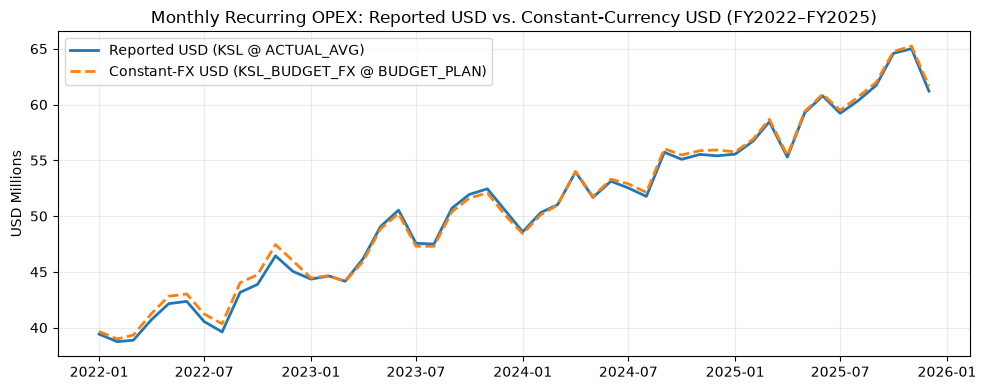

In [3]:
sched = audit_res["special_items_schedule"]
sched_summary = (
    sched.groupby(["SCHEDULE_BUCKET", "RYEAR", "SPECIAL_ITEM_FLAG"], as_index=False)
    .agg(LINES=("BELNR", "count"), KSL_USD=("KSL", "sum"), CONSTANT_FX_USD=("KSL_BUDGET_FX", "sum"))
    .rename(columns={"RYEAR": "LEDGER_FISCAL_YEAR"})
)
display(sched_summary)

fx_df = hygiene["monthly_fx_variance"].copy()
fx_df["PERIOD_DATE"] = pd.to_datetime(dict(year=fx_df["RYEAR"], month=fx_df["POPER"], day=1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(fx_df["PERIOD_DATE"], fx_df["KSL"] / 1e6, label="Reported USD (KSL @ ACTUAL_AVG)", linewidth=2)
ax.plot(fx_df["PERIOD_DATE"], fx_df["KSL_BUDGET_FX"] / 1e6, label="Constant-FX USD (KSL_BUDGET_FX @ BUDGET_PLAN)", linestyle="--", linewidth=2)
ax.set_title("Monthly Recurring OPEX: Reported USD vs. Constant-Currency USD (FY2022–FY2025)")
ax.set_ylabel("USD Millions")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Point-in-Time (`CPUDT`) Close-Window Demonstration (`2025-06-10` vs. `2025-06-30`)

In [4]:
jun10_clean = audit_universal_journal(cutoff_date="2025-06-10", uj_df=uj_raw, dim_gl=dim_gl)["clean_opex"]
jun30_clean = audit_universal_journal(cutoff_date="2025-06-30", uj_df=uj_raw, dim_gl=dim_gl)["clean_opex"]
full_clean = audit_res["clean_opex"]

jun_rows = []
for label, df_sub in [
    ("Cutoff 2025-06-10 (Mid-Month)", jun10_clean),
    ("Cutoff 2025-06-30 (Month-End)", jun30_clean),
    ("Full Closed Actuals (Incl. July Close)", full_clean),
]:
    m6 = df_sub[(df_sub["RYEAR"] == 2025) & (df_sub["POPER"] == 6)]
    jun_rows.append({
        "SNAPSHOT_CUTOFF": label,
        "JUNE_2025_LINES": len(m6),
        "JUNE_2025_KSL_BUDGET_FX": round(float(m6["KSL_BUDGET_FX"].sum()), 2),
    })

pd.DataFrame(jun_rows)

,SNAPSHOT_CUTOFF,JUNE_2025_LINES,JUNE_2025_KSL_BUDGET_FX
0,Cutoff 2025-06-10 (Mid-Month),173,"9,368,774.71"
1,Cutoff 2025-06-30 (Month-End),686,"55,056,927.33"
2,Full Closed Actuals (Incl. July Close),802,"60,928,908.51"


## 5. Single-Snapshot `COOI` & Causal Feature Panel Preview

In [5]:
artifacts = build_monthly_opex_panel(uj_df=uj_raw, dim_gl=dim_gl)
panel = artifacts["opex_monthly_panel"]

print(f"Exported panel: {len(panel):,} rows x {panel.shape[1]} cols -> {PROCESSED_DATA_DIR / 'opex_monthly_panel.parquet'}")
print(f"Non-zero PO_OPEN_COMMIT_T_MINUS_1 rows: {int((panel['PO_OPEN_COMMIT_T_MINUS_1'] > 0).sum()):,}")

readable_preview = rename_to_readable(panel.head(10), table_name="acdoca_universal_journal")
readable_preview[[
    "LEDGER_FISCAL_YEAR", "POSTING_PERIOD", "COMPANY_CODE", "COST_CENTER_ID",
    "GL_ACCOUNT_ID", "COST_BEHAVIOR", "AMOUNT_USD_CONSTANT_FX_SIGNED",
    "LAG_1M", "PO_OPEN_COMMIT_T_MINUS_1", "BP_KSL_BUDGET", "YTD_BUDGET_UTILIZATION_LAG1"
]]

Exported panel: 9,408 rows x 64 cols -> D:\Code Projects\opex_forecast\data\processed\opex_monthly_panel.parquet
Non-zero PO_OPEN_COMMIT_T_MINUS_1 rows: 3,744


,LEDGER_FISCAL_YEAR,POSTING_PERIOD,COMPANY_CODE,COST_CENTER_ID,GL_ACCOUNT_ID,COST_BEHAVIOR,AMOUNT_USD_CONSTANT_FX_SIGNED,LAG_1M,PO_OPEN_COMMIT_T_MINUS_1,BP_KSL_BUDGET,YTD_BUDGET_UTILIZATION_LAG1
0,2022,1,US10,CC1010,610010,STEP_FIXED,"853,752.88",NaN,0.00,"831,599.92",NaN
1,2022,1,US10,CC1010,610020,STEP_FIXED,"249,299.04",NaN,0.00,"230,573.69",NaN
2,2022,1,US10,CC1010,610030,VARIABLE,"155,504.22",NaN,0.00,"165,366.43",NaN
3,2022,1,US10,CC1010,620010,VARIABLE,"1,992,254.86",NaN,"1,842,273.77","1,969,400.96",NaN
4,2022,1,US10,CC1010,620020,VARIABLE,"646,235.32",NaN,"559,388.88","666,195.67",NaN
5,2022,1,US10,CC1010,620030,MILESTONE,0.00,NaN,0.00,0.00,NaN
6,2022,1,US10,CC1010,620040,VARIABLE,"195,521.69",NaN,"188,195.96","177,361.34",NaN
7,2022,1,US10,CC1010,620050,VARIABLE,"133,267.76",NaN,"130,031.20","140,039.68",NaN
8,2022,1,US10,CC1010,620060,MILESTONE,"25,255.43",NaN,0.00,"24,125.32",NaN
9,2022,1,US10,CC1010,620070,FIXED,"202,928.13",NaN,0.00,"208,638.32",NaN


## 6. Exact Raw-to-Parquet Dollar Tie-Out Assertion

In [6]:
panel_disk = pd.read_parquet(PROCESSED_DATA_DIR / "opex_monthly_panel.parquet")
ksl_diff = abs(float(panel_disk["KSL"].sum()) - float(full_clean["KSL"].sum()))
const_diff = abs(float(panel_disk["KSL_BUDGET_FX"].sum()) - float(full_clean["KSL_BUDGET_FX"].sum()))

assert ksl_diff < 0.01, f"KSL tie-out failed: {ksl_diff}"
assert const_diff < 0.01, f"KSL_BUDGET_FX tie-out failed: {const_diff}"
print(f"TIE-OUT PASSED | KSL diff=${ksl_diff:.6f} | KSL_BUDGET_FX diff=${const_diff:.6f}")
print(f"Total 4-Year Recurring OPEX Constant-FX USD: ${panel_disk['KSL_BUDGET_FX'].sum():,.2f}")

TIE-OUT PASSED | KSL diff=$0.000000 | KSL_BUDGET_FX diff=$0.000000
Total 4-Year Recurring OPEX Constant-FX USD: $2,443,715,922.02
